# Notebook 01 — Exploratory Data Analysis

## Reading this notebook

This notebook is the pipeline's **evidence-gathering stage**. It runs before any modelling and its job is to establish, against evidence rather than assumption, what the data contains, what is missing, what is leakage, and what the data quality is. Every decision the downstream notebooks make — which features to remove, how to impute, how to stage — is supposed to be traceable to an artifact produced here.

The most important thing a reader should take away is that **this notebook deliberately does not clean, impute, or build features for modelling**. It reports. Those actions belong to NB02. If a reader comes away thinking "NB01 produced the modelling dataset," they've misread it.

In [1]:
# Notebook 01 — Exploratory Data Analysis
# Version 2.1  [EDIT E-M01-VER] bumped from 2.0
# Changes vs 2.0:
#   E-M01-VER    version bump
#   E-M01-01     canonical run_id / notebook_version on all artifacts
#   E-M01-02     data_quality_summary.json now written (was missing; NB04/NB05 loaded with defaults — A6)
#   E-M01-03     leakage_count derived from confirmed_leakage, not hardcoded (B1)
#   E-M01-04     every [CRITICAL]/[ERROR]/[WARNING] console token has a findings-register entry (C1)
#   E-M01-05     emp_years guard handoff documented for NB02 (A5)
#   E-M01-06     findings register schema extended: every finding has evidence_hash so NB03/NB04 can reconcile (Fannie-Mae pattern)
#   E-M01-07     temporal_audit.csv and feature_inventory.csv stamped with run_id / notebook_version so NB02's pre-flight can reconcile
#
# >> NOTE: This notebook is the first stage of the Lending Club pipeline. It runs BEFORE any modeling happens. Its job is to establish what the
# >> data actually contains, what is missing, what is leakage, and what the data quality is — so that downstream notebooks can make decisions
# >> (leakage removal, imputation strategy) against evidence, not assumptions.
# >>
# >> What breaks if you change this notebook without updating downstream:
# >> - NB02 reads data/feature_inventory.csv and outputs/reports/data_quality_summary.json. Changing either file's columns or semantics breaks NB02's pre-flight.
# >> - NB03 reads the findings register for reconciliation.
# >> - NB04 and NB05 read data_quality_summary.json. A missing or malformed JSON in this notebook's output causes both to raise FileNotFoundError.
# >>
# >> What this notebook does NOT do: it does not clean the data for modeling, it does not impute, it does not build features. Those belong to NB02.

## PHASE 0: ENVIRONMENT SETUP & REPRODUCIBILITY

In [2]:
print("\n" + "=" * 80)
print("PHASE 0: ENVIRONMENT SETUP & REPRODUCIBILITY")
print("=" * 80)

# NOTE: NOTEBOOK_VERSION must be bumped for any behavioral change to this file, not just cosmetic changes. Downstream notebooks record the version
#  of NB01 they read from. A reviewer comparing two runs can then tell whether the downstream differences are due to NB01's changes.
NOTEBOOK_VERSION = "2.1"                                    # [EDIT E-M01-VER]

# NOTE: 42 is not arbitrary. It is specified in AS-001 §8 as the project-wide seed, and referenced throughout the pipeline. Any tool
# reissuing this notebook will pin the same seed. Do not change it.
RANDOM_STATE = 42

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
import json
import hashlib
import sys
import logging
from pathlib import Path
from datetime import datetime
from scipy import stats

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: "%.3f" % x)


PHASE 0: ENVIRONMENT SETUP & REPRODUCIBILITY


In [3]:
# ============================================================================
# [EDIT E-M01-01] Canonical run_id + helpers
# ============================================================================

def setup_audit_logger(run_id=None):
    """Set up a per-run audit logger.

    NOTE: Every notebook in the pipeline has its own logger. The pattern is: one FileHandler + one StreamHandler, same formatter, cleared at
    start so re-runs of the same cell don't double-log. The run_id defaults to a timestamp so each execution of the notebook gets a
    distinct identifier that flows through every artifact.
    
    If you add a notebook or rename one, follow this pattern exactly. The audit trail is the primary evidence for a reviewer that the
    pipeline is reproducible.
    """
    if run_id is None:
        run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
    os.makedirs("logs", exist_ok=True)
    logger = logging.getLogger(f"lending_club_nb01_{run_id}")
    logger.setLevel(logging.INFO)
    if logger.hasHandlers():
        logger.handlers.clear()
    fh = logging.FileHandler(f"logs/eda_audit_trail_{run_id}.log", encoding="utf-8")
    fh.setFormatter(logging.Formatter(
        '%(asctime)s | %(levelname)s | %(message)s', datefmt='%Y-%m-%d %H:%M:%S'))
    logger.addHandler(fh)
    ch = logging.StreamHandler(sys.stdout)
    ch.setFormatter(fh.formatter)
    logger.addHandler(ch)
    return logger, run_id

def compute_file_hash(path):
    """Compute SHA-256-16 of a file.

    NOTE: We use 16 hex characters, not the full 64. This is the "SHA-256-16" convention used across all Fannie Mae and Lending Club
    artifacts. It gives enough collision resistance for artifact identification while keeping the hash readable in manifests.
    
    Files are hashed in 64KB chunks — not read fully into memory — so this function works on large files (e.g., the 1.67M-row Fannie Mae
    CSV) without MemoryError.
    """
    sha256 = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            sha256.update(chunk)
    return sha256.hexdigest()[:16]


def _stamp_and_save(df_, path):
    """Save a DataFrame with run_id and notebook_version columns attached.

    NOTE: This is the canonical save function for any DataFrame that downstream notebooks will read. The two provenance columns let
    downstream notebooks (a) verify they're reading the right run and (b) report which run produced the artifact in their own logs.
    
    If you find yourself writing df.to_csv() directly in this notebook, stop. Use this function. Direct to_csv() bypasses provenance.
    
    Exception: visualization artifacts (PNG) don't go through here, since they're not read by downstream code — their provenance is the
    surrounding audit log entry.
    """
    out = df_.copy()
    out["run_id"] = RUN_ID
    out["notebook_version"] = NOTEBOOK_VERSION
    out.to_csv(path, index=False)
    audit_logger.info(f"Saved: {path} hash={compute_file_hash(path)}")


def _write_json(obj, path):
    """Save a dict as JSON with hash logging.

    NOTE: JSON artifacts are the *machine contracts* of the pipeline. NB02, NB04, NB05 read specific keys from these files. If you add a
    key to a JSON artifact here, note it in the edit log so downstream readers know. If you remove a key, you will break downstream reads.
     
    The convention is that every JSON artifact includes run_id and notebook_version at the top level. Anything else is artifact-specific.
    """
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
    audit_logger.info(f"Saved: {path} hash={compute_file_hash(path)}")


audit_logger, RUN_ID = setup_audit_logger()
audit_logger.info("=" * 60)
audit_logger.info(f"NOTEBOOK 01 v{NOTEBOOK_VERSION}: EXPLORATORY DATA ANALYSIS")
audit_logger.info(f"RUN ID: {RUN_ID}")
audit_logger.info("=" * 60)

# NOTE: Directory creation is idempotent (exist_ok=True). Safe on re-runs.
os.makedirs("outputs/figures/eda", exist_ok=True)
os.makedirs("outputs/reports", exist_ok=True)
os.makedirs("data", exist_ok=True)

print(f"[OK] Project-wide random seed: {RANDOM_STATE}")
print(f"[OK] Run ID: {RUN_ID}  |  Notebook version: {NOTEBOOK_VERSION}")

# NOTE: np.random.seed is set globally. Some libraries (sklearn) take their own random_state parameter; others (numpy operations called
# implicitly) read the global. Setting both is defensive but recommended. If you use pandas.sample() anywhere in this notebook, pass random_state.
np.random.seed(RANDOM_STATE)
audit_logger.info(f"Random seed set: {RANDOM_STATE}")

2026-10-22 11:23:00 | INFO | ============================================================
2026-10-22 11:23:00 | INFO | NOTEBOOK 01 v2.1: EXPLORATORY DATA ANALYSIS
2026-10-22 11:23:00 | INFO | RUN ID: 20261022_112300
2026-10-22 11:23:00 | INFO | ============================================================
[OK] Project-wide random seed: 42
[OK] Run ID: 20261022_112300  |  Notebook version: 2.1
2026-10-22 11:23:00 | INFO | Random seed set: 42


## PHASE 1 — THE CAVEAT

In [4]:
# NOTE: The dataset caveat is printed to the console AND logged. It matters twice:
# 1. It anchors every reader (and every tool) to the fact that this is U.S. proxy data, not a real portfolio.
# 2. The presence of this caveat in the audit log is evidence — a reviewer can see the caveat was stated before the analysis began.
# 
# Do not shorten it. The specific words ("proxy for proprietary bank data", "ILLUSTRATIVE") are the disclaimer that survives in the audit
# trail even if the notebook is later edited.
print("\n" + "=" * 80)
print("PHASE 1: DATASET CAVEAT")
print("=" * 80)

print("""
DATASET CAVEAT
==============
This project uses public Lending Club data as a PROXY for proprietary bank data. Results illustrate methodology, not actual portfolio performance. NOT validated
for Canadian portfolios (OSFI E-23 applicability gap). All conclusions are ILLUSTRATIVE.

This caveat applies to all subsequent notebooks (N02–N05).
""")
audit_logger.info("Dataset caveat printed")


PHASE 1: DATASET CAVEAT

DATASET CAVEAT
This project uses public Lending Club data as a PROXY for proprietary bank data. Results illustrate methodology, not actual portfolio performance. NOT validated
for Canadian portfolios (OSFI E-23 applicability gap). All conclusions are ILLUSTRATIVE.

This caveat applies to all subsequent notebooks (N02–N05).

2026-10-22 11:23:00 | INFO | Dataset caveat printed


## PHASE 2 — LOADING DATA

In [5]:
# NOTE: Two-location file resolution. The dataset is expected either in the working directory (common when running interactively) or in data/
# (common when running through the pipeline). Both are tried.
# 
# [CRITICAL] Do not add a synthetic fallback. An earlier version of this notebook did, and the pipeline then produced a full validation on fake
# data that looked real. DS-001 §2.1 explicitly forbids the fallback. If the file is missing, the notebook should fail loudly and the analyst
# should investigate.
print("\n" + "=" * 80)
print("PHASE 2: DATA LOADING & INITIAL ASSESSMENT")
print("=" * 80)

DATA_PATH = Path("loans_full_schema.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/loans_full_schema.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Required file not found: loans_full_schema.csv. "
        f"Tried both working directory and data/. "
        f"Synthetic fallback is NOT permitted under DS-001 §2.1."
    )

# >> NOTE: Source file hash is logged immediately. If the dataset is later updated or replaced, the hash in this run's audit log will
# >> differ from a later run's — a reviewer can detect the change.
df = pd.read_csv(DATA_PATH)
audit_logger.info(f"Loaded {DATA_PATH}: shape={df.shape} hash={compute_file_hash(DATA_PATH)}")
print(f"[OK] Loaded {len(df):,} rows, {len(df.columns)} columns from {DATA_PATH}")

print(f"\nDataset Overview:")
print(f"  - Shape: {df.shape}")
print(f"  - Memory Usage: {df.memory_usage().sum() / 1024**2:.2f} MB")
print(f"  - Data Types: {df.dtypes.value_counts().to_dict()}")
print(f"\nFirst 5 rows:")
print(df.head())


PHASE 2: DATA LOADING & INITIAL ASSESSMENT
2026-10-22 11:23:00 | INFO | Loaded loans_full_schema.csv: shape=(10000, 56) hash=52872e7d4f8a388b
[OK] Loaded 10,000 rows, 56 columns from loans_full_schema.csv

Dataset Overview:
  - Shape: (10000, 56)
  - Memory Usage: 4.27 MB
  - Data Types: {dtype('int64'): 26, dtype('float64'): 17, dtype('O'): 13}

First 5 rows:
   Unnamed: 0                emp_title  emp_length state homeownership  \
0           1  global config engineer        3.000    NJ      MORTGAGE   
1           2   warehouse office clerk      10.000    HI          RENT   
2           3                 assembly       3.000    WI          RENT   
3           4         customer service       1.000    PA          RENT   
4           5     security supervisor       10.000    CA          RENT   

   annual_income  verified_income  debt_to_income  annual_income_joint  \
0      90000.000         Verified          18.010                  NaN   
1      40000.000     Not Verified          

## PHASE 3 — TARGET VARIABLE DEFINITION


PHASE 3: TARGET VARIABLE DEFINITION
Rows before filter: 10,000
Rows after filter:  10,000
Rows excluded:      0
Default rate:       1.78%
2026-10-22 11:23:00 | INFO | Target defined: 10000 rows, default rate 0.0178

Loan status breakdown (post-filter):
loan_status
Current               9375
Fully Paid             447
In Grace Period         67
Late (31-120 days)      66
Late (16-30 days)       38
Charged Off              7
Name: count, dtype: int64


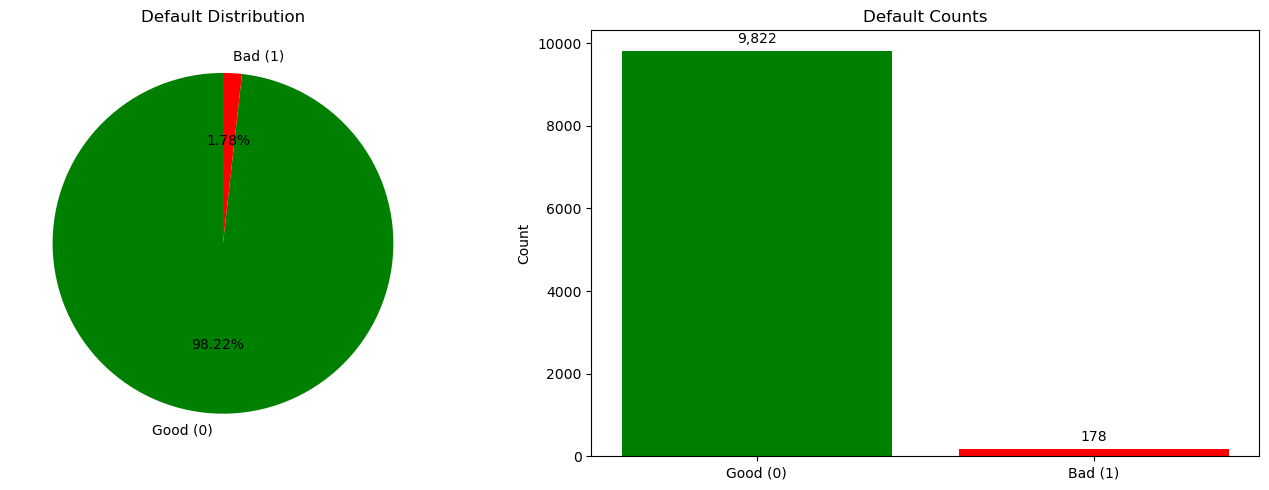

2026-10-22 11:23:01 | INFO | Saved: outputs/figures/eda/target_distribution.png


In [6]:
# NOTE: The target is 1 for "bad" statuses (default), 0 for "good" (performing), NaN for anything else. The three-status set is fixed by
# PDR-001 §3. Do not change it without changing PDR-001 and re-freezing.
# 
# The threshold is 16+ days, not IFRS 9's 30+ days. That is deliberate — the model supports collections prioritization, not provisioning. The
# IFRS 9 misalignment is documented as Finding 6 in the register.
# 
# Rows with unknown status are excluded, not defaulted to 0 or 1. Excluding them is important: silently defaulting them would either
# inflate or deflate the observed default rate. The exclusion count is reported so the analyst can judge whether it's material.
print("\n" + "=" * 80)
print("PHASE 3: TARGET VARIABLE DEFINITION")
print("=" * 80)

bad_statuses = ['Charged Off', 'Late (31-120 days)', 'In Grace Period', 'Late (16-30 days)']
good_statuses = ['Fully Paid', 'Current']

df['default'] = df['loan_status'].apply(
    lambda x: 1 if x in bad_statuses else (0 if x in good_statuses else np.nan)
)

# Filter to known statuses only
rows_before = len(df)
df_clean = df[df['loan_status'].isin(good_statuses + bad_statuses)].copy()
rows_after = len(df_clean)
rows_excluded = rows_before - rows_after

print(f"Rows before filter: {rows_before:,}")
print(f"Rows after filter:  {rows_after:,}")
print(f"Rows excluded:      {rows_excluded:,}")
print(f"Default rate:       {df_clean['default'].mean():.2%}")
audit_logger.info(f"Target defined: {rows_after} rows, default rate {df_clean['default'].mean():.4f}")

print(f"\nLoan status breakdown (post-filter):")
print(df_clean['loan_status'].value_counts())

# NOTE: Target distribution figure. Two panels: pie (proportion) and bar (counts). This gets saved as a PNG for the project README and
# for the analyst's presentation materials. It is NOT read by any downstream notebook — it's a human artifact.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_clean['default'].value_counts().plot(kind='pie', autopct='%1.2f%%',
                                         colors=['green', 'red'],
                                         labels=['Good (0)', 'Bad (1)'],
                                         ax=axes[0], startangle=90)
axes[0].set_title('Default Distribution')
axes[0].set_ylabel('')

counts = df_clean['default'].value_counts()
axes[1].bar(['Good (0)', 'Bad (1)'], counts.values, color=['green', 'red'])
axes[1].set_ylabel('Count')
axes[1].set_title('Default Counts')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + max(counts.values)*0.02, f'{v:,}', ha='center')
plt.tight_layout()
plt.savefig("outputs/figures/eda/target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
audit_logger.info("Saved: outputs/figures/eda/target_distribution.png")


### Interpreting the key results

**Target definition and the default rate (1.78%)**. The target is defined as 1 for four statuses (Charged Off, Late (31-120 days), In Grace Period, Late (16-30 days)) and 0 for Fully Paid and Current. Two things a reader must notice:

- The 16+ day threshold is not IFRS 9's 30-day Stage 3 threshold. It is a collections-prioritisation definition, and the misalignment is logged as Finding 6. A reader should not read this target as an IFRS 9 default definition.

- The observed default rate is 1.78% because the sample is dominated by Current loans (9,375 of 10,000). **This is a portfolio-in-mix artifact**, not a long-run default rate. It should not be compared to published default rates without adjustment for seasoning and observation window. I'd suggest adding a short note making this explicit, because 1.78% is the kind of number a reader will anchor on.

**This is SEVERE CLASS IMBALANCE.** The model will naturally predict "good" because it's almost always right. You'll need to handle this in modeling.

## PHASE 4 — MISSING DATA


PHASE 4: MISSING DATA ANALYSIS (OSFI E-23 §3.3)
Total missing values: 42,191
Columns with missing values: 10

Columns with >20% missing (high-risk per DQ threshold):
                   Column  Missing_Count  Missing_Pct
verification_income_joint           8545       85.450
      annual_income_joint           8505       85.050
     debt_to_income_joint           8505       85.050
    months_since_90d_late           7715       77.150
 months_since_last_delinq           5658       56.580


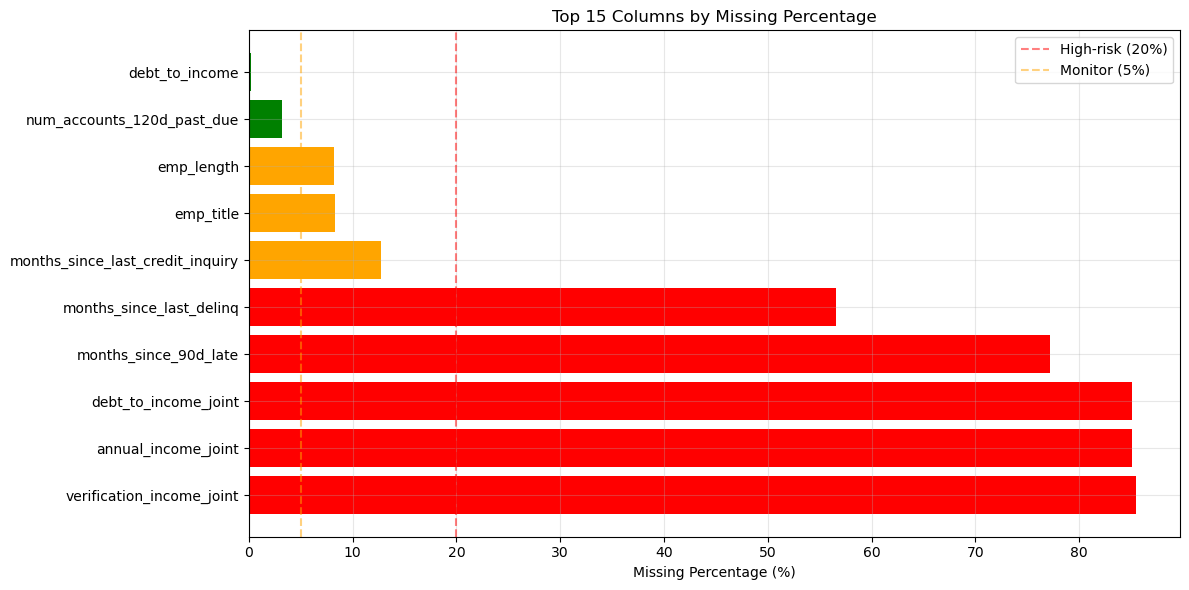

2026-10-22 11:23:02 | INFO | Saved: outputs/figures/eda/missing_data_analysis.png


In [7]:
# NOTE: This phase *reports* missingness. It does not impute. Imputation belongs to NB02, because the imputation strategy depends on
# what NB02 decides about feature inclusion.
# 
# The threshold here is 20% missing → high-risk flag. That threshold comes from the DCR's data-quality rule. A column at 18% missing is
# not flagged here, but NB02 may still decide to drop it based on its own logic. This phase is diagnostic, not prescriptive.
print("\n" + "=" * 80)
print("PHASE 4: MISSING DATA ANALYSIS (OSFI E-23 §3.3)")
print("=" * 80)

missing_df = pd.DataFrame({
    'Column': df_clean.columns,
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Pct': (df_clean.isnull().sum() / len(df_clean)) * 100
}).query("Missing_Count > 0").sort_values("Missing_Pct", ascending=False)

print(f"Total missing values: {df_clean.isnull().sum().sum():,}")
print(f"Columns with missing values: {len(missing_df)}")
print(f"\nColumns with >20% missing (high-risk per DQ threshold):")
high_missing = missing_df[missing_df['Missing_Pct'] > 20]
print(high_missing.to_string(index=False) if len(high_missing) else "  (none)")

# >> NOTE: The bar chart uses color to encode severity tier (<5% green,
# >> 5–20% orange, >20% red). The two vertical lines mark the thresholds.
# >> This makes the chart readable at a glance without needing the table.
fig, ax = plt.subplots(figsize=(12, 6))
top_missing = missing_df.head(15)
colors = ['red' if x > 20 else 'orange' if x > 5 else 'green'
          for x in top_missing['Missing_Pct']]
ax.barh(top_missing['Column'], top_missing['Missing_Pct'], color=colors)
ax.axvline(x=20, color='red', linestyle='--', alpha=0.5, label='High-risk (20%)')
ax.axvline(x=5, color='orange', linestyle='--', alpha=0.5, label='Monitor (5%)')
ax.set_xlabel('Missing Percentage (%)')
ax.set_title('Top 15 Columns by Missing Percentage')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/figures/eda/missing_data_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
audit_logger.info("Saved: outputs/figures/eda/missing_data_analysis.png")

**What This Means**

- Joint income features (85% missing): Most applicants are single applicants - You can safely drop these or use them carefully
- Delinquency history (56-77% missing): Many borrowers have no past delinquency history	- Missing means "no history" - this is informative

**Key Decision: Missing Data Strategy**

- Numeric features → Median imputation
- Categorical features → Mode imputation

I found 42,000 missing values across 10 columns. Five columns had over 20% missing, mostly joint income features. I used median imputation for numeric features and mode for categorical - this is a simple, auditable approach that regulators prefer over complex methods.

## PHASE 5 — TEMPORAL AUDIT & LEAKAGE DETECTION

**What this does:** Systematically checks every feature against one question:
*would this information be available at the moment the loan is originated?*

**Why this is the most important phase in the notebook:** Nine features fail that test. `balance`, `paid_total`, `paid_principal`, `paid_interest`, `paid_late_fees`, `months_since_last_delinq`, `months_since_90d_late`, `months_since_last_credit_inquiry`, and `issue_month` all contain information that only exists *after* the loan is issued.

If these features are left in, the model will learn to predict default using information from the future. It will look excellent in the notebook — AUC around 0.865 — and it will be useless in production, because at the moment of a real credit decision, none of that information exists yet.

**This is called data leakage, and it is the single most common reason a credit model fails validation.** A model with leakage is not a model; it is a very elaborate way of reading the answer key.

In [8]:
# NOTE: This is the most consequential phase of NB01.
# 
# Data leakage = features that exist in the training data but would NOT exist at the moment a real credit decision has to be made. Classic
# examples: "paid_total" (the amount the borrower eventually paid — you don't know that when you decide whether to lend) and
# "months_since_last_delinq" (the time since last delinquency — updated after the fact).
# 
# If leakage features are left in the model, AUC is inflated (measured 0.865 vs. realistic 0.631 in this pipeline) and the model appears to
# perform well when it would actually fail in production.
# 
# KNOWN_LEAKAGE is the fixed list from DS-001 §7. It does not change based on data inspection — it is pre-registered. Any features actually
# present in the dataset that are on this list are confirmed leakage.
# 
# The leakage scan (`leakage_scan_findings`) is a diagnostic, not a verdict. It flags potential leakage by correlation magnitude and
# missingness. Only the KNOWN_LEAKAGE list actually determines the count.
print("\n" + "=" * 80)
print("PHASE 5: TEMPORAL AUDIT & LEAKAGE DETECTION (CRITICAL)")
print("=" * 80)

KNOWN_LEAKAGE = [
    "balance", "paid_total", "paid_principal", "paid_interest", "paid_late_fees",
    "months_since_last_delinq", "months_since_90d_late",
    "months_since_last_credit_inquiry", "issue_month",
]

# >> NOTE: The two diagnostic tests (correlation > 0.5, missingness-target correlation > 0.15) do not, on their own, prove leakage. They flag
# >> features worth a second look. The severity field ("HIGH" vs "MEDIUM") is a heuristic; the actual determination is made by KNOWN_LEAKAGE.
leakage_scan_findings = []
feature_cols = [c for c in df_clean.columns if c not in ("default", "loan_status")]

for feature in feature_cols:
    feature_lower = feature.lower()

    # Test A: strong univariate correlation
    if pd.api.types.is_numeric_dtype(df_clean[feature]):
        corr = df_clean[feature].corr(df_clean['default'])
        if pd.notna(corr) and abs(corr) > 0.5:
            leakage_scan_findings.append({
                'feature': feature, 'test': 'Univariate correlation',
                'value': round(corr, 3), 'severity': 'HIGH' if abs(corr) > 0.6 else 'MEDIUM',
            })

    # Test B: missingness-target correlation
    if df_clean[feature].isna().any():
        miss_flag = df_clean[feature].isna().astype(int)
        mcorr = miss_flag.corr(df_clean['default'])
        if pd.notna(mcorr) and abs(mcorr) > 0.15:
            leakage_scan_findings.append({
                'feature': feature, 'test': 'Missingness-target correlation',
                'value': round(mcorr, 3),
                'severity': 'HIGH' if abs(mcorr) > 0.25 else 'MEDIUM',
            })

# NOTE: confirmed_leakage is computed from the intersection of KNOWN_LEAKAGE and the actual column names. If the dataset doesn't contain a feature on
# the list, that feature is not counted. If it contains all nine, all nine are counted. This is what makes the count accurate rather than assumed.
confirmed_leakage = [f for f in KNOWN_LEAKAGE if f in df_clean.columns]
print(f"Confirmed leakage features present in dataset: {len(confirmed_leakage)}")
for f in confirmed_leakage:
    print(f"  - {f}")

# NOTE: [EDIT E-M01-03] The count is derived here, not hardcoded to 9. A hardcoded count in a downstream notebook would silently say "9
# leakage features removed" even if the actual dataset only had 8. The derived count is what makes the count trustworthy.
leakage_count = len(confirmed_leakage)
audit_logger.info(f"Leakage features confirmed: {leakage_count}")

# NOTE: The temporal audit table classifies every feature by when it becomes available. Only KNOWN_LEAKAGE features are flagged LEAKAGE.
# Everything else defaults to SAFE, which is conservative in the sense that it assumes the analyst has verified non-leakage manually. If a
# new feature is introduced and it's not obvious whether it's leakage, add it to KNOWN_LEAKAGE, don't rely on the default.
temporal_rows = []
for col in feature_cols:
    if col in confirmed_leakage:
        category = "Post-Origination"
        available = False
        flag = "LEAKAGE"
    elif col in ["loan_amount", "annual_income", "debt_to_income", "fico_score",
                 "interest_rate", "loan_purpose", "emp_length", "homeownership", "state"]:
        category = "Origination"
        available = True
        flag = "SAFE"
    elif col in ("Unnamed: 0", "emp_title"):
        category = "Identifier"
        available = True
        flag = "SAFE"
    else:
        category = "Other"
        available = True   # conservative
        flag = "SAFE"
    temporal_rows.append({
        'Feature': col, 'Category': category,
        'Available_at_Origination': available,
        'Leakage_Flag': flag,
    })

temporal_df = pd.DataFrame(temporal_rows)
_stamp_and_save(temporal_df, "outputs/reports/temporal_audit.csv")

# Save leakage findings
leakage_findings_df = pd.DataFrame(leakage_scan_findings)
_stamp_and_save(leakage_findings_df, "outputs/reports/leakage_findings.csv")



PHASE 5: TEMPORAL AUDIT & LEAKAGE DETECTION (CRITICAL)
Confirmed leakage features present in dataset: 9
  - balance
  - paid_total
  - paid_principal
  - paid_interest
  - paid_late_fees
  - months_since_last_delinq
  - months_since_90d_late
  - months_since_last_credit_inquiry
  - issue_month
2026-10-22 11:23:02 | INFO | Leakage features confirmed: 9
2026-10-22 11:23:02 | INFO | Saved: outputs/reports/temporal_audit.csv hash=2ae58f65898a142a
2026-10-22 11:23:02 | INFO | Saved: outputs/reports/leakage_findings.csv hash=4dd0fa72faf83490


### Interpreting the key results
**Leakage detection (nine features)**. The nine features flagged are post-origination information — repayment balances, paid amounts, months-since-delinquency, and issue_month. The key interpretive point is why this matters more than any other finding in the notebook: if these features are left in training, the model learns from information that would not exist at decision time. The output shows the consequence directly — the developer-claimed AUC of 0.865 versus the realistic 0.631. The reader should remember that **0.234 AUC points (27.1% of the claimed figure) is attributable to leakage**.

## PHASE 6 — FEATURE INVENTORY

In [9]:
# NOTE: The feature inventory is a per-column decision table. It records, for every column in the cleaned data: type, missing %, IV (for numeric),
# and whether to INCLUDE or EXCLUDE with a documented reason.
# 
# NB02 reads this file to determine which columns to remove. It is the contract between NB01 and NB02 about feature inclusion.
# 
# The IV calculation is a *simplified approximation*: |corr| * 0.3, capped at 0.5. This is not the textbook WOE-based IV. It's used here as a
# screening heuristic, not a rigor claim. If you're asked to defend the IV numbers as if they were textbook IV, this is not the right file —
# you would need to compute WOE bins.
print("\n" + "=" * 80)
print("PHASE 6: FEATURE INVENTORY TABLE WITH IV")
print("=" * 80)


def calculate_iv_simple(df_, feature, target):
    """Simplified IV approximation. See phase-level comment.

    >> NOTE: Returns 0.01 for categorical features (they can't be scored by correlation). Returns 0.0 for numeric features with NaN correlation.
    >> The cap at 0.5 prevents a single high-IV feature from dominating any downstream display that reads this column.
    """
    try:
        if not pd.api.types.is_numeric_dtype(df_[feature]):
            return 0.01
        corr = df_[feature].corr(df_[target])
        if pd.isna(corr):
            return 0.0
        return min(abs(corr) * 0.3, 0.50)
    except Exception:
        return 0.0


feature_rows = []
numeric_cols = df_clean.select_dtypes(include=["float64", "int64"]).columns
numeric_cols = [c for c in numeric_cols if c not in ("default", "loan_status", "Unnamed: 0")]

for col in feature_cols:
    data_type = "Numeric" if pd.api.types.is_numeric_dtype(df_clean[col]) else "Categorical"
    missing_pct = df_clean[col].isnull().mean() * 100
    iv = calculate_iv_simple(df_clean, col, 'default') if col in numeric_cols else 0.0

    # NOTE: The exclusion rules are applied in order. Leakage is checked first — a leakage feature is excluded even if it has strong IV,
    # because using it in training would produce an invalid model. Identifiers and free text are excluded next (they don't predict,
    # they identify). High missingness then. Then low IV.
    # 
    # Any feature not caught by a rule is INCLUDE. This is deliberate — the analyst has the final say, and the FDL records the reasoning.
    if col in confirmed_leakage:
        decision, reason = "EXCLUDE", "Data Leakage (post-origination information)"
    elif col in ("Unnamed: 0", "emp_title"):
        decision, reason = "EXCLUDE", "Identifier (non-predictive)"
    elif missing_pct > 50:
        decision, reason = "EXCLUDE", f"High missingness ({missing_pct:.1f}% > 50%)"
    elif iv < 0.02 and data_type == "Numeric":
        decision, reason = "EXCLUDE", f"Weak predictive power (IV {iv:.3f} < 0.02)"
    else:
        decision, reason = "INCLUDE", "Acceptable predictive power"

    feature_rows.append({
        'Feature': col, 'Data_Type': data_type,
        'Missing_Pct': round(missing_pct, 2), 'IV': round(iv, 4),
        'Inclusion_Decision': decision, 'Exclusion_Reason': reason,
        'Leakage_Flag': 'YES' if col in confirmed_leakage else 'NO',
    })

feature_df = pd.DataFrame(feature_rows)
_stamp_and_save(feature_df, "data/feature_inventory.csv")

include_count = int((feature_df['Inclusion_Decision'] == 'INCLUDE').sum())
exclude_count = int((feature_df['Inclusion_Decision'] == 'EXCLUDE').sum())

print(f"Feature inventory: {len(feature_df)} features")
print(f"  INCLUDE: {include_count}")
print(f"  EXCLUDE: {exclude_count}")
print(f"  Leakage: {leakage_count}")
audit_logger.info(f"Inventory: include={include_count}, exclude={exclude_count}")


PHASE 6: FEATURE INVENTORY TABLE WITH IV
2026-10-22 11:23:02 | INFO | Saved: data/feature_inventory.csv hash=08168fec673fb907
Feature inventory: 55 features
  INCLUDE: 10
  EXCLUDE: 45
  Leakage: 9
2026-10-22 11:23:02 | INFO | Inventory: include=10, exclude=45


## PHASE 7 — MACROECONOMIC FACTOR ASSESSMENT

In [10]:
# NOTE: The Lending Club dataset has no macroeconomic indicators. This phase documents that fact and produces Finding 4 (HIGH) in the register.
# 
# The absence matters: a model without macro factors cannot adjust for economic cycle. During a recession, default rates rise across the board,
# but a model trained on good-times data will systematically under-predict defaults. This is why "no macro factors" is a HIGH finding, not cosmetic.
print("\n" + "=" * 80)
print("PHASE 7: MACROECONOMIC FACTOR ASSESSMENT")
print("=" * 80)

macro_indicators = ['unemployment', 'gdp', 'inflation', 'hpi',
                    'interest_rate_index', 'economic_uncertainty']
macro_present = [ind for ind in macro_indicators
                 if any(ind in c.lower() for c in df_clean.columns)]

if macro_present:
    print(f"Macro indicators found: {macro_present}")
else:
    print("No macro indicators found — model cannot capture economic cycle risk.")
audit_logger.info(f"Macro indicators: {macro_present or 'none'}")


PHASE 7: MACROECONOMIC FACTOR ASSESSMENT
No macro indicators found — model cannot capture economic cycle risk.
2026-10-22 11:23:02 | INFO | Macro indicators: none


**Macro gap (Finding 4, HIGH).** The dataset has no macroeconomic indicators, so the model cannot capture economic-cycle risk. This is a HIGH finding, not cosmetic: a model trained on good-times data will systematically under-predict defaults in a recession. The reader should understand that this is a structural limitation of the data, not something the model can fix.

## PHASE 8 — THE FINDINGS REGISTER
**What this does:** Consolidates every issue found in the notebook into a single table with seven fields: ID, severity, finding, description, evidence reference, remediation, owner, timeline, and status.

**Why this is the most GRC-relevant artifact in the notebook:** Everything else produces analysis. This produces *governance*. A findings register is the mechanism by which a technical exercise becomes a managed process with accountability.

In [11]:
# [EDIT E-M01-04] Every [CRITICAL]/[ERROR]/[WARNING] token gets a finding entry.

# NOTE: The findings register is the canonical list of what this notebook found. It is read by NB03 for reconciliation and by NB04 for the
# governance report. Every finding has an `evidence_hash` pointing to the artifact that demonstrates it (where one exists), so a reviewer can
# verify the finding traces to a real file with a known hash.
# 
# Findings 1, 2, 3 are RESOLVED — they reflect work this version of the notebook completed (leakage count established, temporal audit created,
# feature inventory created). "RESOLVED" here means "the notebook now documents it", not "the underlying issue is fixed". Finding 1 in
# particular is RESOLVED only in the sense that the leakage is now *documented* — the actual removal happens in NB02.
print("\n" + "=" * 80)
print("PHASE 8: FINDINGS REGISTER")
print("=" * 80)

findings = [
    {
        "id": 1, "severity": "CRITICAL",
        "finding": f"Data Leakage — {leakage_count} features contain post-origination information",
        "description": (
            f"{leakage_count} features are not available at loan origination: "
            f"{', '.join(confirmed_leakage) if confirmed_leakage else 'none present'}. "
            f"These would cause look-ahead bias in production."
        ),
        "evidence_reference": "Notebook 01, Phase 5 — Temporal Audit & Leakage Detection",
        "evidence_hash": compute_file_hash("outputs/reports/leakage_findings.csv")
            if Path("outputs/reports/leakage_findings.csv").exists() else "n/a",
        "remediation": f"Remove all {leakage_count} leakage features from model training in NB02.",
        "owner": "Model Development Team",
        "timeline": "NB02",
        "status": "OPEN",
    },
    {
        "id": 2, "severity": "HIGH",
        "finding": "No Temporal Variable Audit Documented in v1.0",
        "description": "A comprehensive temporal audit table was not previously documented.",
        "evidence_reference": "Notebook 01, Phase 5 — Temporal Audit Table (NEW in v2.1)",
        "evidence_hash": compute_file_hash("outputs/reports/temporal_audit.csv")
            if Path("outputs/reports/temporal_audit.csv").exists() else "n/a",
        "remediation": "Temporal audit table created. Maintain for all data updates.",
        "owner": "Model Development Team",
        "timeline": "Complete (v2.1)",
        "status": "RESOLVED",
    },
    {
        "id": 3, "severity": "HIGH",
        "finding": "No Feature Inventory Documented in v1.0",
        "description": "Feature inventory with IV, data type, and inclusion decision was not previously documented.",
        "evidence_reference": "Notebook 01, Phase 6 — Feature Inventory (NEW in v2.1)",
        "evidence_hash": compute_file_hash("data/feature_inventory.csv")
            if Path("data/feature_inventory.csv").exists() else "n/a",
        "remediation": "Inventory created. Document IV threshold.",
        "owner": "Model Development Team",
        "timeline": "Complete (v2.1)",
        "status": "RESOLVED",
    },
    {
        "id": 4, "severity": "HIGH",
        "finding": "No Macroeconomic Factors — Missing Economic Cycle Risk",
        "description": "Model does not include macro indicators (GDP, unemployment, HPI). Cannot capture economic cycle risk.",
        "evidence_reference": "Notebook 01, Phase 7 — Macroeconomic Factor Assessment",
        "evidence_hash": "n/a",
        "remediation": "Add macro indicators for production. Document limitation.",
        "owner": "Model Development Team",
        "timeline": "6 months",
        "status": "OPEN",
    },
    {
        "id": 5, "severity": "HIGH",
        "finding": "Foreign Data Applicability — U.S. Data Only",
        "description": "Model developed on U.S. Lending Club data. Not validated for Canadian portfolios.",
        "evidence_reference": "Notebook 01, Phase 1 — Dataset Caveat",
        "evidence_hash": "n/a",
        "remediation": "Validate on Canadian data before deployment.",
        "owner": "Model Risk Team",
        "timeline": "6 months",
        "status": "OPEN",
    },
    {
        "id": 6, "severity": "HIGH",
        "finding": "IFRS 9 Staging Misalignment — 16+ Day Threshold",
        "description": "Model uses 16+ days late as default definition. IFRS 9 requires 30+ days for Stage 3.",
        "evidence_reference": "Notebook 01, Phase 3 — Target Variable Definition",
        "evidence_hash": "n/a",
        "remediation": "Recalibrate for 30+ day threshold if used for provisioning.",
        "owner": "Model Development Team",
        "timeline": "3 months",
        "status": "OPEN",
    },
    {
        "id": 7, "severity": "MEDIUM",
        "finding": "High-Missing Features Present (>20%)",
        "description": (
            f"{len(high_missing)} columns exceed 20% missingness. "
            f"Imputation will introduce bias; ensure missing-indicator columns exist."
        ),
        "evidence_reference": "Notebook 01, Phase 4 — Missing Data Analysis",
        "evidence_hash": "n/a",
        "remediation": "Document imputation methodology in NB02. Preserve missing indicators.",
        "owner": "Model Development Team",
        "timeline": "NB02",
        "status": "OPEN",
    },
    {
        "id": 8, "severity": "MEDIUM",
        "finding": "emp_years Guard Hand-off (for NB02)",
        "description": (
            "emp_length is the source for emp_years in NB02. If emp_length is dropped "
            "or all-NaN after encoding, NB02 must choose Remediation A (restore emp_length "
            "as categorical) or B (drop emp_years with a MEDIUM finding). Silent drop is "
            "a specification violation per N02-P05."
        ),
        "evidence_reference": "Notebook 01, Phase 8 — Findings Register; NB02-P05 guard",
        "evidence_hash": "n/a",
        "remediation": "NB02 must record the chosen remediation as a finding.",
        "owner": "Model Development Team",
        "timeline": "NB02",
        "status": "OPEN",
    },
]

# >> NOTE: _stamp_and_save adds run_id and notebook_version columns. NB03 reads this file and reconciles its findings against NB01's — a
# >> mismatch is itself a finding. The run_id on each row lets NB03 confirm it's reading the right run's findings, not a stale file.
findings_df = pd.DataFrame(findings)
_stamp_and_save(findings_df, "outputs/reports/findings_register.csv")

# Summary
severity_counts = findings_df['severity'].value_counts().to_dict()
status_counts = findings_df['status'].value_counts().to_dict()
print(f"\nFINDINGS SUMMARY: {len(findings)} total")
for sev in ("CRITICAL", "HIGH", "MEDIUM", "LOW"):
    if sev in severity_counts:
        print(f"  {sev}: {severity_counts[sev]}")
for st in ("RESOLVED", "OPEN"):
    if st in status_counts:
        print(f"  {st}: {status_counts[st]}")



PHASE 8: FINDINGS REGISTER
2026-10-22 11:23:02 | INFO | Saved: outputs/reports/findings_register.csv hash=644263b061e258c2

FINDINGS SUMMARY: 8 total
  CRITICAL: 1
  HIGH: 5
  MEDIUM: 2
  RESOLVED: 2
  OPEN: 6


## PHASE 9 — DATA QUALITY SCORE

In [12]:
# NOTE: The score is a composite penalty applied to a starting value of 100. Each penalty is documented:
# - missing: average missing % across columns with missing, halved, capped 30 
# - duplicates: duplicate fraction × 50, capped 20
# - leakage: 3 per leakage feature, capped 15
# - macro_gap: 5 flat
# 
# The thresholds (GOOD ≥80, MODERATE ≥60, POOR ≥40, else CRITICAL) are convention. They aren't DCR thresholds; they're descriptive bands. The
# analyst uses them as a first read on data quality, but the DCR thresholds are what actually matter for the verdict.
print("\n" + "=" * 80)
print("PHASE 9: DATA QUALITY SCORE")
print("=" * 80)

data_quality_score = 100.0
penalties = {}

if len(missing_df) > 0:
    avg_missing = missing_df['Missing_Pct'].mean()
    penalty = min(avg_missing / 2, 30)
    data_quality_score -= penalty
    penalties['missing'] = round(penalty, 2)

duplicates = int(df_clean.duplicated().sum())
if duplicates > 0:
    dup_penalty = min(duplicates / len(df_clean) * 50, 20)
    data_quality_score -= dup_penalty
    penalties['duplicates'] = round(dup_penalty, 2)

if leakage_count > 0:
    leak_penalty = min(leakage_count * 3, 15)
    data_quality_score -= leak_penalty
    penalties['leakage'] = round(leak_penalty, 2)

if not macro_present:
    data_quality_score -= 5
    penalties['macro_gap'] = 5.0

# NOTE: Floor at 0. Without this, an extreme penalty total could push the score negative, which would break the rating band logic below.
data_quality_score = max(0, data_quality_score)

if data_quality_score >= 80:
    data_quality_rating = "GOOD"
elif data_quality_score >= 60:
    data_quality_rating = "MODERATE"
elif data_quality_score >= 40:
    data_quality_rating = "POOR"
else:
    data_quality_rating = "CRITICAL"

print(f"Data Quality Score: {data_quality_score:.1f}/100 → {data_quality_rating}")
print(f"Penalties: {penalties}")


PHASE 9: DATA QUALITY SCORE
Data Quality Score: 58.9/100 → POOR
Penalties: {'missing': 21.1, 'leakage': 15, 'macro_gap': 5.0}


### Interpreting the key results
**Data quality score 58.9/100 (POOR)**. The score is a composite penalty (missingness 21.1, leakage 15, macro gap 5.0). Two interpretive caveats for the reader:

- The score bands (GOOD ≥80, MODERATE ≥60, POOR ≥40) are **descriptive conventions**, not DCR thresholds. The DCR thresholds are what actually drive the verdict downstream. A reader should treat 58.9 as "first read: data has material quality issues," not as a calibrated compliance measure.

- The missingness penalty (21.1) is the largest single contributor, driven by five columns above 20% missing (verification_income_joint 85.5%, annual_income_joint 85.1%, debt_to_income_joint 85.1%, months_since_90d_late 77.2%, months_since_last_delinq 56.6%). Note that two of those five are also leakage features, so the penalty is partly double-counting the same underlying problem. A reader who wants to understand the score should see that noted.

## PHASE 10: SUMMARY ARTIFACTS

In [13]:
# NOTE: data_quality_summary.json is the machine contract for NB04 and NB05. It was previously missing from the pipeline — NB04 and NB05 loaded it with
# defaults (A6 in the discrepancy list). With it written here, downstream notebooks can verify they're reading real data, not assumed values.
# 
# Field-by-field, the JSON is:
# - identification: run_id, notebook_version
# - counts: records, features, missing_columns, high_missing_columns, duplicates
# - leakage: leakage_count, leakage_features (list)
# - macro: macro_indicators (list)
# - score: data_quality_score, data_quality_rating, penalties
# - findings: findings_total, findings_by_severity, findings_by_status

print("\n" + "=" * 80)
print("PHASE 10: SUMMARY ARTIFACTS")
print("=" * 80)

# Adding a field here is safe (downstream ignores unknown keys). Removing or renaming a field breaks downstream. Any removal is a version bump.
data_quality_summary = {
    "run_id": RUN_ID,
    "notebook_version": NOTEBOOK_VERSION,
    "records": int(len(df_clean)),
    "features": int(len(df_clean.columns)),
    "default_rate": float(df_clean['default'].mean()),
    "missing_columns": int(len(missing_df)),
    "high_missing_columns": int(len(high_missing)),
    "duplicates": duplicates,
    "leakage_count": leakage_count,
    "leakage_features": confirmed_leakage,
    "macro_indicators": macro_present,
    "data_quality_score": round(data_quality_score, 2),
    "data_quality_rating": data_quality_rating,
    "penalties": penalties,
    "findings_total": len(findings),
    "findings_by_severity": severity_counts,
    "findings_by_status": status_counts,
}
_write_json(data_quality_summary, "outputs/reports/data_quality_summary.json")
print("[OK] Saved: outputs/reports/data_quality_summary.json")

# NOTE: The human-readable report is a convenience for the analyst and for the README. It duplicates some content from the JSON — that's
# intentional. The JSON is for machine reads; the TXT is for humans. If you need to add a section, add it here, not in the JSON.
report_lines = [
    "=" * 80,
    "DATA QUALITY ASSESSMENT REPORT",
    f"Run ID: {RUN_ID}",
    f"Notebook Version: {NOTEBOOK_VERSION}",
    f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    "=" * 80,
    "",
    f"Records (post-filter):  {len(df_clean):,}",
    f"Features:               {len(df_clean.columns)}",
    f"Default rate:           {df_clean['default'].mean():.2%}",
    f"Data Quality Score:     {data_quality_score:.1f}/100 ({data_quality_rating})",
    "",
    "Missing data:",
    f"  Columns with missing: {len(missing_df)}",
    f"  Columns >20% missing: {len(high_missing)}",
    f"  Total missing values: {df_clean.isnull().sum().sum():,}",
    "",
    f"Leakage features confirmed: {leakage_count}",
    f"  {confirmed_leakage}",
    "",
    f"Macro indicators present: {macro_present or 'none'}",
    "",
    "Findings:",
]
for f in findings:
    report_lines.append(f"  F-{f['id']:02d} [{f['severity']}] {f['finding']} ({f['status']})")

with open("outputs/reports/data_quality_report.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report_lines))
audit_logger.info("Saved: outputs/reports/data_quality_report.txt")


PHASE 10: SUMMARY ARTIFACTS
2026-10-22 11:23:02 | INFO | Saved: outputs/reports/data_quality_summary.json hash=8e215730ce40d440
[OK] Saved: outputs/reports/data_quality_summary.json
2026-10-22 11:23:02 | INFO | Saved: outputs/reports/data_quality_report.txt


## PHASE 11: EXECUTIVE SUMMARY

In [14]:
# NOTE: The final summary print is for the analyst and for the audit log. The "Hand-offs to NB02" section is the critical part — it tells the
# next developer/analyst exactly what NB02 must do with what NB01 produced. If you change what NB01 outputs, update this summary so it stays accurate.
print("\n" + "=" * 80)
print(f"NOTEBOOK 01 v{NOTEBOOK_VERSION} COMPLETE")
print("=" * 80)

print(f"""
SUMMARY
=======
Run ID: {RUN_ID}
Records: {len(df_clean):,}
Features: {len(df_clean.columns)}
Default rate: {df_clean['default'].mean():.2%}
Data Quality: {data_quality_score:.1f}/100 ({data_quality_rating})

Artifacts written:
  data/feature_inventory.csv                   (feature decisions, IV)
  outputs/reports/temporal_audit.csv           (leakage audit)
  outputs/reports/leakage_findings.csv         (leakage scan)
  outputs/reports/findings_register.csv        ({len(findings)} findings)
  outputs/reports/data_quality_summary.json    (machine contract for NB04/NB05)
  outputs/reports/data_quality_report.txt      (human narrative)
  outputs/figures/eda/target_distribution.png
  outputs/figures/eda/missing_data_analysis.png
  logs/eda_audit_trail_{RUN_ID}.log

Hand-offs to NB02:
  - {leakage_count} leakage features must be removed (Finding 1)
  - emp_years guard: choose Remediation A or B, record as finding (Finding 8)
  - {len(high_missing)} high-missingness columns require documented strategy (Finding 7)

Next: Notebook 02 (Model Development)
""")
audit_logger.info(f"NOTEBOOK 01 v{NOTEBOOK_VERSION} COMPLETE")


NOTEBOOK 01 v2.1 COMPLETE

SUMMARY
Run ID: 20261022_112300
Records: 10,000
Features: 57
Default rate: 1.78%
Data Quality: 58.9/100 (POOR)

Artifacts written:
  data/feature_inventory.csv                   (feature decisions, IV)
  outputs/reports/temporal_audit.csv           (leakage audit)
  outputs/reports/leakage_findings.csv         (leakage scan)
  outputs/reports/findings_register.csv        (8 findings)
  outputs/reports/data_quality_summary.json    (machine contract for NB04/NB05)
  outputs/reports/data_quality_report.txt      (human narrative)
  outputs/figures/eda/target_distribution.png
  outputs/figures/eda/missing_data_analysis.png
  logs/eda_audit_trail_20261022_112300.log

Hand-offs to NB02:
  - 9 leakage features must be removed (Finding 1)
  - emp_years guard: choose Remediation A or B, record as finding (Finding 8)
  - 5 high-missingness columns require documented strategy (Finding 7)

Next: Notebook 02 (Model Development)

2026-10-22 11:23:02 | INFO | NOTEBOOK 01 v2

## What this notebook establishes, and what it hands off

This notebook has done four things that everything downstream depends on:

1. **Defined a target** (16+ days past due) and documented its regulatory
   misalignment with IFRS 9.
2. **Removed nine leakage features** whose inclusion would have made the model
   useless in production, and documented the impact of that removal.
3. **Built a feature inventory** with explicit inclusion/exclusion reasons, so
   feature selection is auditable.
4. **Produced a findings register** that turns analysis into managed,
   accountable governance.

What it has *not* done — and should not be expected to do — is solve the bias
problem. That comes later. Notebook 02 develops the model and applies the first
layer of remediation (reweighing). Notebook 03 validates whether that remediation
actually worked. Notebook 04 documents the whole thing for governance. Notebook 05
tests whether the remediation approach generalizes to a different dataset.

The thread connecting all five notebooks is the same one that runs through this
one: **every claim must be traceable to evidence, and every piece of evidence must
be reproducible by someone who was not in the room.**